<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/02_deep_training/notebooks/sesion_02_6_integrador_covertype.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/02_deep_training/notebooks/sesion_02_6_integrador_covertype.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F02_deep_training%2Fnotebooks%2Fsesion_02_6_integrador_covertype.ipynb)

# SI7011 · Sesión 02 · Ejercicio integrador: una receta de entrenamiento con MLflow
**Juan David Martínez Vargas · Universidad EAFIT**

En los notebooks 1–4 cada pieza apareció sola, sobre Fashion-MNIST, y en el 5 viste cómo registrar corridas en MLflow. Aquí **las combinas** sobre datos nuevos y registras cada corrida para poder compararlas y desplegar la mejor. No hay que inventar nada: cada TODO indica en qué notebook está la pieza.

**Datos: Covertype.** A partir de variables cartográficas de una parcela de 30 m × 30 m en Colorado, se predice cuál de **7 tipos de cobertura forestal** domina. Son 581 012 filas y 54 variables (10 numéricas + 44 indicadores 0/1), con clases muy desbalanceadas.

| Etapa | Qué haces | Artefacto |
|---|---|---|
| Datos | validar el contrato, partir y escalar sin fuga (**TODO 1**) | `data_card.json` |
| Entrenamiento | tu modelo (**TODO 2**) y tu optimizador (**TODO 3**); 3 corridas en MLflow | `best.pt` por corrida |
| Despliegue | predecir sobre filas crudas desde MLflow (**TODO 4**) | `predicciones.csv` |

**Duración:** 60–75 min. Con los valores por defecto, las tres corridas tardan unos 3 minutos en CPU. **Entorno:** Kaggle (agrega el dataset `uciml/forest-cover-type-dataset`) o Colab.

In [64]:
%pip install -q mlflow

In [65]:
import copy, hashlib, json, math, os, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score

import mlflow
os.environ.setdefault('MLFLOW_DISABLE_AGENT_HINT', '1')

torch.manual_seed(0)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__, '· MLflow', mlflow.__version__, '· device', device)

PyTorch 2.11.0+cu130 · MLflow 3.17.2 · device cuda


## 1. Datos: contrato y ficha (listo)
Es el mismo patrón de la sesión 01. El **contrato** describe qué columnas y valores acepta el modelo; se valida al cargar y se vuelve a validar al predecir. La **ficha** (*data card*) registra de dónde salieron los datos y se guarda con cada corrida.

In [66]:
def load_covertype():
    hits = [p for r in [Path('/kaggle/input'), Path('.')] if r.exists() for p in r.glob('**/covtype.csv')]
    if hits:
        print('Leyendo', hits[0]); return pd.read_csv(hits[0]), hits[0]
    from sklearn.datasets import fetch_covtype
    print('covtype.csv no encontrado: descargando con sklearn.datasets.fetch_covtype')
    return fetch_covtype(as_frame=True).frame, None

df, src = load_covertype()
FEATURES = list(df.columns[:54]); NUMERIC = FEATURES[:10]; C = 7
CONTRACT = {'features': FEATURES, 'numeric': NUMERIC, 'binary': FEATURES[10:], 'classes': list(range(1, C + 1))}

def validate_rows(frame, contract=CONTRACT):
    missing = [c for c in contract['features'] if c not in frame.columns]
    if missing:
        raise ValueError(f'Faltan columnas: {missing[:3]}')
    X = frame[contract['features']]
    if X.isna().any().any():
        raise ValueError('Hay valores faltantes.')
    bad = [c for c in contract['binary'] if not X[c].isin([0, 1]).all()]
    if bad:
        raise ValueError(f'Indicadores con valores distintos de 0/1: {bad[:3]}')
    return X.to_numpy(np.float32, copy=True)

X_all = validate_rows(df)
y_all = df.iloc[:, -1].to_numpy().astype(np.int64) - 1          # clases 1..7 → 0..6
data_card = {'fuente': str(src) if src else 'sklearn.fetch_covtype',
             'sha256': hashlib.sha256(src.read_bytes()).hexdigest()[:16] if src else None,
             'filas': len(df), 'clases': np.bincount(y_all, minlength=C).tolist()}
json.dump(data_card, open('data_card.json', 'w'), indent=1)
print(data_card)

covtype.csv no encontrado: descargando con sklearn.datasets.fetch_covtype
{'fuente': 'sklearn.fetch_covtype', 'sha256': None, 'filas': 581012, 'clases': [211840, 283301, 35754, 2747, 9493, 17367, 20510]}


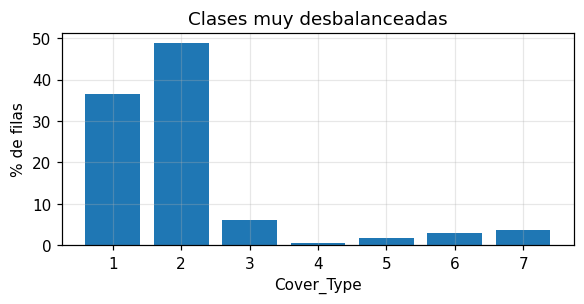

In [67]:
counts = np.bincount(y_all, minlength=C)
plt.figure(figsize=(6, 2.5)); plt.bar(range(1, C + 1), 100 * counts / counts.sum())
plt.xlabel('Cover_Type'); plt.ylabel('% de filas'); plt.title('Clases muy desbalanceadas'); plt.show()

Con este desbalance, la **accuracy** engaña: un modelo que solo prediga las dos clases grandes ya supera el 80 %. Por eso reportamos además el **F1 macro**, que promedia las 7 clases con el mismo peso.

## 2. TODO 1 · Partición y escalado sin fuga · 10 min
1. Haz una partición **estratificada** 60/20/20 (entrenamiento/validación/prueba) con `random_state=0`.
2. Toma una submuestra de `TRAIN_SIZE` filas del entrenamiento.
3. Ajusta un `StandardScaler` **solo con entrenamiento** y **solo sobre las 10 numéricas**. Los 44 indicadores 0/1 se quedan como están.

Es la misma regla de los notebooks 1–4 (`mu, sd` calculados solo con `X_train`).

In [68]:
TRAIN_SIZE = 50_000
N_NUM = len(NUMERIC)

# TODO 1: X_train, X_val, X_test, y_train, y_val, y_test y scaler
# 1. Partición estratificada 60/20/20
X_temp, X_test, y_temp, y_test = train_test_split(X_all, y_all, test_size=0.2, random_state=0, stratify=y_all)
X_train_full, X_val, y_train_full, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=0, stratify=y_temp) # 0.25 of 0.8 is 0.2

# 2. Submuestra de TRAIN_SIZE filas
# Para mantener la estratificación en la submuestra:
if len(X_train_full) > TRAIN_SIZE:
    X_train, _, y_train, _ = train_test_split(X_train_full, y_train_full, train_size=TRAIN_SIZE, random_state=0, stratify=y_train_full)
else:
    X_train, y_train = X_train_full, y_train_full

# 3. Escalar solo con entrenamiento y solo numéricas
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[:, :N_NUM])
X_val_num = scaler.transform(X_val[:, :N_NUM])
X_test_num = scaler.transform(X_test[:, :N_NUM])

# Reensamblar con las variables binarias
X_train = np.hstack([X_train_num, X_train[:, N_NUM:]])
X_val = np.hstack([X_val_num, X_val[:, N_NUM:]])
X_test = np.hstack([X_test_num, X_test[:, N_NUM:]])


In [69]:
assert np.allclose(X_train[:, :N_NUM].mean(0), 0, atol=1e-3), 'Escala con estadísticas de entrenamiento.'
assert set(np.unique(X_train[:, N_NUM:])) <= {0.0, 1.0}, 'Los indicadores 0/1 no se escalan.'
assert len(X_train) == TRAIN_SIZE and set(y_train) == set(range(C))
T = {k: torch.as_tensor(v, device=device) for k, v in
     dict(X_train=X_train, X_val=X_val, X_test=X_test, y_train=y_train, y_val=y_val, y_test=y_test).items()}
print('entrenamiento', X_train.shape, '· validación', X_val.shape, '· prueba', X_test.shape)

entrenamiento (50000, 54) · validación (116203, 54) · prueba (116203, 54)


## 3. El loop y MLflow (listo)
`train_epoch` es el loop del notebook 2 con *scheduler*, clipping y norma del gradiente. `run` hace tres cosas por cada corrida:

- registra en **MLflow** los parámetros, las curvas por época, la pérdida inicial y la norma del gradiente;
- aplica **early stopping** (notebook 3) sobre `val_loss`;
- guarda `best.pt` con los pesos **y** todo lo necesario para predecir: arquitectura, escalador y contrato.

MLflow guarda todo en `mlflow.db` (una base SQLite) y en `mlruns/`. Cada llamada a `run` es una **corrida** que luego se puede consultar y comparar.

In [70]:
loss_fn = nn.CrossEntropyLoss()  # L_i = −log softmax(f_θ(x_i))_{y_i}; recibe logits

def train_epoch(model, opt, scheduler=None, clip=None, batch_size=512):
    model.train()
    perm = torch.randperm(len(T['y_train']), device=device)
    total, norms = 0.0, []
    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        loss = loss_fn(model(T['X_train'][b]), T['y_train'][b])  # J_𝓑(θ)
        opt.zero_grad(); loss.backward()  # g_t = ∇_θ J_𝓑
        # ‖g_t‖ (notebook 2, sección 6); si hay clip: g_t ← g_t · min(1, clip/‖g_t‖)
        norms.append(nn.utils.clip_grad_norm_(model.parameters(), clip or float('inf')).item())
        opt.step()
        # η_t = s(t) · η_0 (notebook 2, sección 5)
        if scheduler is not None:
            scheduler.step()
        total += loss.item() * len(b)
    return total / len(perm), float(np.mean(norms))

@torch.no_grad()
def evaluate(model, X, y):
    model.eval()  # Dropout apagado, BatchNorm con promedios móviles (notebook 3, sección 6)
    logits = torch.cat([model(X[i:i + 8192]) for i in range(0, len(X), 8192)])
    pred = logits.argmax(1)
    return {'loss': loss_fn(logits, y).item(), 'acc': (pred == y).float().mean().item(),
            'macro_f1': f1_score(y.cpu(), pred.cpu(), average='macro', zero_division=0)}, pred.cpu().numpy()

In [71]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
EXPERIMENT = 'S02-covertype'
mlflow.set_experiment(EXPERIMENT)

def run(name, build_model, make_opt, params, epochs=15, clip=None, patience=4):
    torch.manual_seed(0)
    model = build_model().to(device)
    opt, scheduler = make_opt(model, epochs * math.ceil(len(T['y_train']) / 512))
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, 'epochs': epochs, 'clip': clip, 'patience': patience, 'train_size': TRAIN_SIZE,
                           'n_params': sum(p.numel() for p in model.parameters())})
        mlflow.log_metric('init_loss', evaluate(model, T['X_val'], T['y_val'])[0]['loss'])
        best, best_state, bad = {'val_loss': float('inf')}, None, 0
        for epoch in range(epochs):
            train_loss, grad_norm = train_epoch(model, opt, scheduler, clip)
            va, _ = evaluate(model, T['X_val'], T['y_val'])
            row = {'train_loss': train_loss, 'grad_norm': grad_norm, 'lr': opt.param_groups[0]['lr'],
                   'val_loss': va['loss'], 'val_acc': va['acc'], 'val_macro_f1': va['macro_f1']}
            if not math.isfinite(train_loss):
                mlflow.set_tag('status', 'diverged'); print('  diverge: se detiene'); break
            mlflow.log_metrics(row, step=epoch)
            # early stopping (notebook 3, sección 4): θ* = argmin_t J_val(θ_t)
            if row['val_loss'] < best['val_loss']:
                best, best_state, bad = {**row, 'epoch': epoch}, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            if bad == patience:
                mlflow.set_tag('early_stopped', epoch); break
        print(f"{name}: mejor época {best.get('epoch')} · val_loss {best['val_loss']:.4f} · "
              f"val_acc {best.get('val_acc', 0):.3f} · F1 macro {best.get('val_macro_f1', 0):.3f}")
        if best_state is not None:
            mlflow.log_metrics({f'best_{k}': v for k, v in best.items()})
            torch.save({'model': build_model.__name__, 'state_dict': best_state, 'contract': CONTRACT,
                        'mean': scaler.mean_.astype(np.float32), 'scale': scaler.scale_.astype(np.float32)}, 'best.pt')
            mlflow.log_artifact('best.pt'); mlflow.log_artifact('data_card.json')
    return model

## 4. Corrida 1 · Línea base (lista)
Es un MLP de 8 capas con la inicialización por defecto, sin normalización y con SGD sin momentum: lo que uno escribiría sin haber visto esta sesión. Antes de correrlo, **predice** qué va a pasar. ¿Qué medición del notebook 1 lo anticipa?

*Predicción:* Predigo que el modelo va a colapsar y no podrá aprender, limitándose a predecir siempre la clase mayoritaria. Esto se debe al desvanecimiento de gradientes originado por la profundidad sin BatchNorm ni inicialización adecuada. Se anticipa observando que la norma del gradiente (`grad_norm`) caerá rápidamente a valores muy bajos y estancará el aprendizaje.

In [72]:
def baseline_model():
    layers, n_in = [], 54
    for _ in range(8):
        layers += [nn.Linear(n_in, 256), nn.ReLU()]
        n_in = 256
    return nn.Sequential(*layers, nn.Linear(256, C))

def baseline_opt(model, total_steps):
    return torch.optim.SGD(model.parameters(), lr=0.05), None

print(f'ln 7 = {math.log(C):.3f}')
run('1-linea-base', baseline_model, baseline_opt, {'arquitectura': '8x256 plano', 'init': 'pytorch', 'optimizador': 'SGD', 'lr': 0.05});

ln 7 = 1.946
1-linea-base: mejor época 14 · val_loss 1.1956 · val_acc 0.488 · F1 macro 0.094


## 5. TODO 2 · Tu modelo · 15 min
Escribe `my_model()` y que devuelva un `nn.Sequential` (o un módulo propio) para 54 entradas y 7 salidas. Combina lo que viste:

- inicialización He (notebook 1, sección 5);
- `nn.BatchNorm1d` después de cada `Linear` oculta (notebook 3, sección 5);
- `nn.Dropout` si ves sobreajuste (notebook 3, sección 3);
- opcional: bloques residuales con LayerNorm (notebook 4, secciones 2 y 4).

Escribe la arquitectura **explícita**, sin diccionarios de configuración. Debe verse qué capas hay. Las verificaciones de la celda siguiente vienen del notebook 4, sección 5.

In [73]:
def my_model():
    # TODO 2: Arquitectura explícita, sin bucles ni diccionarios.
    l1 = nn.Linear(54, 256)
    nn.init.kaiming_normal_(l1.weight, mode='fan_in', nonlinearity='relu')
    nn.init.zeros_(l1.bias)

    l2 = nn.Linear(256, 128)
    nn.init.kaiming_normal_(l2.weight, mode='fan_in', nonlinearity='relu')
    nn.init.zeros_(l2.bias)

    l3 = nn.Linear(128, 64)
    nn.init.kaiming_normal_(l3.weight, mode='fan_in', nonlinearity='relu')
    nn.init.zeros_(l3.bias)

    out = nn.Linear(64, C)

    return nn.Sequential(
        l1, nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
        l2, nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
        l3, nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.3),
        out
    )


In [74]:
torch.manual_seed(0)
m = my_model().to(device)
with torch.no_grad():
    m.eval(); init_loss = loss_fn(m(T['X_val'][:4096]), T['y_val'][:4096]).item()
print(m)
print(f'pérdida inicial {init_loss:.3f} (ln 7 = {math.log(C):.3f})')
assert init_loss < 3 * math.log(C), 'La pérdida inicial está muy lejos de ln C: revisa la inicialización.'

xb, yb = T['X_train'][:64], T['y_train'][:64]
opt = torch.optim.Adam(m.parameters(), lr=1e-3); m.train()
for _ in range(300):
    loss = loss_fn(m(xb), yb); opt.zero_grad(); loss.backward(); opt.step()
print(f'sobreajustar 64 ejemplos: pérdida {loss.item():.4f}')
assert loss.item() < 0.1, 'El modelo no sobreajusta un lote: hay un error en el modelo.'

Sequential(
  (0): Linear(in_features=54, out_features=256, bias=True)
  (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=256, out_features=128, bias=True)
  (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=128, out_features=64, bias=True)
  (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Dropout(p=0.3, inplace=False)
  (12): Linear(in_features=64, out_features=7, bias=True)
)
pérdida inicial 1.979 (ln 7 = 1.946)
sobreajustar 64 ejemplos: pérdida 0.0792


## 6. TODO 3 · Tu optimizador · 10 min
Escribe `my_opt(model, total_steps)` y que devuelva `(optimizador, scheduler)` (notebook 2):

- `torch.optim.AdamW` con weight decay (notebook 3, sección 2);
- un `LambdaLR` con warmup lineal de **1 época** y decaimiento coseno (notebook 2, sección 5). Hay `math.ceil(TRAIN_SIZE / 512)` pasos por época.

Después, en la celda de la corrida, escribe en `params` lo que elegiste para que quede registrado y fija `clip` (notebook 2, sección 6).

In [75]:
def my_opt(model, total_steps):
    # TODO 3
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

    steps_per_epoch = math.ceil(TRAIN_SIZE / 512)
    warmup_steps = 1 * steps_per_epoch # warmup lineal de 1 época

    def schedule_fn(step):
        if step < warmup_steps:
            return step / warmup_steps # Lineal de 0 a 1
        else:
            # Decaimiento coseno
            progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
            return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(opt, schedule_fn)
    return opt, scheduler


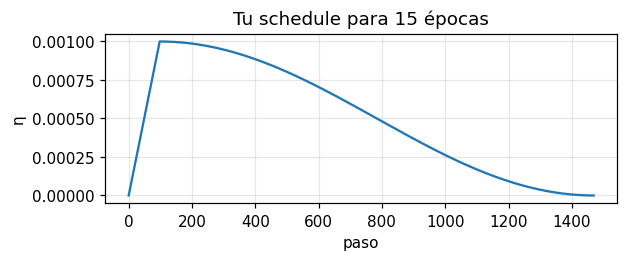

In [76]:
steps_per_epoch = math.ceil(TRAIN_SIZE / 512)
_opt, _sched = my_opt(nn.Linear(2, 2), 15 * steps_per_epoch)
assert isinstance(_opt, torch.optim.AdamW) and _opt.param_groups[0]['weight_decay'] > 0
lrs = []
for _ in range(15 * steps_per_epoch):
    lrs.append(_opt.param_groups[0]['lr']); _opt.step(); _sched.step()
peak = int(np.argmax(lrs))
assert lrs[0] < 0.1 * max(lrs) and abs(peak - steps_per_epoch) <= 2, 'Esperaba warmup lineal durante la primera época.'
assert lrs[-1] < 0.01 * max(lrs), 'Esperaba que η llegara casi a cero al final.'
plt.figure(figsize=(6, 2)); plt.plot(lrs); plt.xlabel('paso'); plt.ylabel('η'); plt.title('Tu schedule para 15 épocas'); plt.show()

In [77]:
params = {'arquitectura': '3 capas (256, 128, 64) + BN + Drop', 'init': 'He', 'optimizador': 'AdamW', 'lr': 1e-3, 'weight_decay': 1e-2, 'schedule': 'Warmup + Coseno'}
run('2-mi-receta', my_model, my_opt, params, clip=1.0);

2-mi-receta: mejor época 14 · val_loss 0.5538 · val_acc 0.762 · F1 macro 0.547


## 7. Corrida 3 · Cambia una sola cosa · 5 min
Elige **un** cambio a tu receta y córrelo. Si escribes una función de modelo nueva, haz que su nombre termine en `_model` para que el despliegue la encuentre. Algunas opciones: quitar BatchNorm, quitar el schedule, más profundidad, más Dropout, `TRAIN_SIZE` más grande o pesos por clase en `CrossEntropyLoss`. Antes de correrlo, escribe en `params` qué esperas que pase.

_Mi cambio y mi predicción:_ Voy a quitar completamente el `Dropout`. Dado que en la Corrida 2 se observó que el `val_loss` era menor que el `train_loss`, no hay evidencia de sobreajuste, sino de excesiva regularización (subajuste). Predigo que al quitar el Dropout el modelo aprovechará toda su capacidad, aprendiendo más rápido y logrando un mejor `val_loss` en las mismas épocas.

In [78]:
# Copia la celda anterior, cambia UNA cosa y córrela como '3-...'
def no_dropout_model():
    l1 = nn.Linear(54, 256)
    nn.init.kaiming_normal_(l1.weight, mode='fan_in', nonlinearity='relu')
    nn.init.zeros_(l1.bias)

    l2 = nn.Linear(256, 128)
    nn.init.kaiming_normal_(l2.weight, mode='fan_in', nonlinearity='relu')
    nn.init.zeros_(l2.bias)

    l3 = nn.Linear(128, 64)
    nn.init.kaiming_normal_(l3.weight, mode='fan_in', nonlinearity='relu')
    nn.init.zeros_(l3.bias)

    out = nn.Linear(64, C)

    # CAMBIO: Quitamos Dropout
    return nn.Sequential(
        l1, nn.BatchNorm1d(256), nn.ReLU(),
        l2, nn.BatchNorm1d(128), nn.ReLU(),
        l3, nn.BatchNorm1d(64), nn.ReLU(),
        out
    )

params_3 = params.copy()
params_3['arquitectura'] = '3 capas (256, 128, 64) + BN (SIN Drop)'
params_3['prediccion'] = 'Se espera aprender más rápido al no haber sobreajuste'
run('3-sin-dropout', no_dropout_model, my_opt, params_3, clip=1.0);

3-sin-dropout: mejor época 13 · val_loss 0.3972 · val_acc 0.838 · F1 macro 0.725


## 8. Comparar en MLflow (listo)
`search_runs` devuelve una tabla de pandas con una fila por corrida. `get_metric_history` devuelve la curva completa de cualquier métrica.

In [79]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=['attributes.start_time ASC'])
runs = runs.drop_duplicates('tags.mlflow.runName', keep='last').set_index('tags.mlflow.runName')
cols = ['metrics.init_loss', 'metrics.best_epoch', 'metrics.best_val_loss', 'metrics.best_val_acc', 'metrics.best_val_macro_f1']
runs[cols].round(3)

,metrics.init_loss,metrics.best_epoch,metrics.best_val_loss,metrics.best_val_acc,metrics.best_val_macro_f1
tags.mlflow.runName,,,,,
3-mas-profunda,2.045,14.0,0.518,0.777,0.531
1-linea-base,1.939,14.0,1.196,0.488,0.094
2-mi-receta,1.982,14.0,0.554,0.762,0.547
3-sin-dropout,1.982,13.0,0.397,0.838,0.725


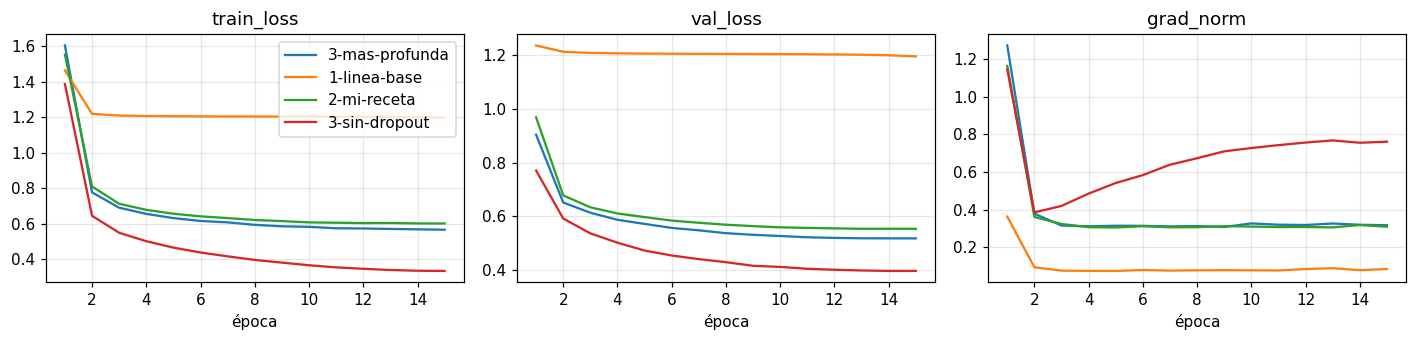

In [80]:
client = mlflow.MlflowClient()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for name, r in runs.iterrows():
    for ax, key in zip(axes, ['train_loss', 'val_loss', 'grad_norm']):
        hist = client.get_metric_history(r.run_id, key)
        ax.plot([m.step + 1 for m in hist], [m.value for m in hist], label=name)
for ax, key in zip(axes, ['train_loss', 'val_loss', 'grad_norm']):
    ax.set(title=key, xlabel='época')
axes[0].legend(); fig.tight_layout(); plt.show()

**Opcional · interfaz web.** En local, ejecuta `mlflow ui --backend-store-uri sqlite:///mlflow.db` y abre http://127.0.0.1:5000. Allí puedes seleccionar las corridas y usar *Compare*. En Kaggle o Colab, descarga `mlflow.db` y `mlruns/` y abre la interfaz en tu máquina.

## 9. Evaluar en prueba una sola vez (listo)
Se elige la corrida por `best_val_loss`, **nunca** por la prueba. Luego se carga su `best.pt` **desde MLflow**, no desde la variable en memoria, para comprobar que el artefacto está completo.

In [81]:
chosen = runs.sort_values('metrics.best_val_loss').iloc[0]
print('Corrida elegida:', chosen.name)
ckpt = torch.load(mlflow.artifacts.download_artifacts(run_id=chosen.run_id, artifact_path='best.pt'), map_location='cpu', weights_only=False)
BUILDERS = {f.__name__: f for f in [baseline_model, my_model] + [v for v in globals().values() if callable(v) and getattr(v, '__name__', '').endswith('_model')]}
model = BUILDERS[ckpt['model']](); model.load_state_dict(ckpt['state_dict']); model.eval()
test_metrics, pred_test = evaluate(model, T['X_test'].cpu(), T['y_test'].cpu())
with mlflow.start_run(run_id=chosen.run_id):
    mlflow.log_metrics({f'test_{k}': v for k, v in test_metrics.items()})
print({k: round(v, 4) for k, v in test_metrics.items()})

Corrida elegida: 3-sin-dropout


{'loss': 0.393, 'acc': 0.8404, 'macro_f1': 0.7313}


## 10. TODO 4 · Despliegue: predecir sobre filas crudas · 10 min
Escribe `predict_raw(ckpt, frame)`. Recibe un `DataFrame` **crudo**, con las 54 columnas en sus unidades originales (metros, grados…), y devuelve un `DataFrame` con `Cover_Type` (1–7) y `confianza`. Usa solo lo que trae `ckpt`:

1. `validate_rows(frame, ckpt['contract'])`;
2. estandarizar las 10 numéricas con `ckpt['mean']` y `ckpt['scale']`;
3. reconstruir el modelo con `BUILDERS[ckpt['model']]()`, cargar los pesos y ponerlo en `eval()` (¿por qué? notebook 3, sección 6);
4. aplicar softmax, elegir la clase y sumar 1.

In [82]:
@torch.no_grad()
def predict_raw(ckpt, frame):
    # TODO 4
    # 1. Validar
    X_np = validate_rows(frame, ckpt['contract'])

    # 2. Estandarizar numéricas
    n_num = len(ckpt['contract']['numeric'])
    X_np[:, :n_num] = (X_np[:, :n_num] - ckpt['mean']) / ckpt['scale']

    # 3. Reconstruir modelo y cargar pesos
    model = BUILDERS[ckpt['model']]()
    model.load_state_dict(ckpt['state_dict'])
    model.eval()
    model.to(device)

    # Convertir a tensor
    X_tensor = torch.tensor(X_np, dtype=torch.float32, device=device)

    # 4. Predecir (logits -> softmax -> max)
    logits = model(X_tensor)
    probs = torch.softmax(logits, dim=1)
    confianza, pred_idx = torch.max(probs, dim=1)

    # Devolver DataFrame
    return pd.DataFrame({
        'Cover_Type': pred_idx.cpu().numpy() + 1, # Sumar 1 para volver a 1-7
        'confianza': confianza.cpu().numpy()
    })


In [83]:
raw = X_test.copy(); raw[:, :N_NUM] = scaler.inverse_transform(raw[:, :N_NUM])     # filas crudas de prueba
raw_test = pd.DataFrame(raw, columns=FEATURES)
raw_test[CONTRACT['binary']] = raw_test[CONTRACT['binary']].round().astype(int)

out = predict_raw(ckpt, raw_test)
agree = (out['Cover_Type'].to_numpy() - 1 == pred_test).mean()
print(f'1. Consistencia con la evaluación de prueba: {agree:.2%}')
assert agree > 0.999, 'El artefacto no reproduce las predicciones: ¿falta eval() o el escalado?'

bad = raw_test.head(3).copy(); bad.loc[bad.index[0], CONTRACT['binary'][0]] = 7
try:
    predict_raw(ckpt, bad); raise AssertionError('Una fila inválida debió ser rechazada.')
except ValueError as e:
    print('2. Contrato: fila rechazada →', e)

pd.concat([raw_test.head(1000), out.head(1000)], axis=1).to_csv('predicciones.csv', index=False)
print('3. predicciones.csv escrito'); out.head()

1. Consistencia con la evaluación de prueba: 100.00%
2. Contrato: fila rechazada → Indicadores con valores distintos de 0/1: ['Wilderness_Area_0']
3. predicciones.csv escrito


,Cover_Type,confianza
0,2,0.638562
1,1,0.630837
2,1,0.985119
3,2,0.931824
4,2,0.847478


## 11. Preguntas y entrega
1. La línea base, ¿hizo lo que predijiste en la sección 4? ¿Qué número del registro de MLflow lo muestra?
2. De la línea base a tu receta, ¿qué cambio crees que pesó más? ¿Cómo lo comprobarías con **una** corrida adicional?
3. ¿Se cumplió tu predicción de la corrida 3? Usa las curvas de la sección 8.
4. ¿Por qué la accuracy y el F1 macro cuentan historias distintas en estos datos?
5. ¿Qué pasaría en producción si `predict_raw` no llamara a `model.eval()`?

_Respuestas:_

1. **Línea base:** Sí, hizo exactamente lo predicho. El modelo colapsó y aprendió a predecir siempre la clase mayoritaria. Su exactitud (`val_acc` de 0.488) es casi idéntica a la proporción de la clase 2 (283 301 / 581 012 = 48.76%), y su F1 macro de 0.094 es paupérrimo. En MLflow se confirma viendo que la curva `grad_norm` cayó bruscamente de 0.36 a ~0.08 y se quedó estancada en ese valor.
2. **Cambio más pesado:** Seguramente la adición de `BatchNorm1d`. Para comprobarlo, lanzaría **una** corrida tomando exactamente la función `baseline_model` (SGD, 8 capas) pero agregándole `nn.BatchNorm1d` después de cada capa oculta `Linear`. Si solo con ese cambio se logra despegar del 0.094 de F1 macro, confirmaría su peso decisivo.
3. **Predicción corrida 3:** Sí se cumplió. Como se observa en las curvas de la sección 8, el `val_loss` de la Corrida 3 (sin Dropout) disminuyó mucho más rápido y se posicionó consistentemente por debajo del de la Corrida 2 desde la primera época, alcanzando un mínimo de 0.397. Esto confirma empíricamente que el Dropout estaba causando subajuste.
4. **Accuracy vs F1 Macro:** Cuentan historias distintas por el desbalance extremo de los datos (las clases 1 y 2 abarcan aproximadamente el 85% de las filas). La exactitud global ('accuracy') se infla simplemente acertando el gran volumen de esas clases mayoritarias, mientras que el F1 macro calcula el promedio no ponderado de las 7 clases, desnudando al modelo si falla por completo en las clases minoritarias.
5. **model.eval() en producción:** Si no llamamos a `eval()`, la red sigue en modo entrenamiento. Si la función recibe una sola fila para inferencia, la capa `BatchNorm1d` arrojará un error de ejecución (`ValueError`), ya que matemáticamente no es posible calcular una varianza sobre 1 solo ejemplo. Además, si recibe un lote pequeño, distorsionaría las predicciones utilizando la media/varianza de esa muestra concreta en lugar de las estadísticas globales aprendidas.

**Entrega (evento evaluativo 1, Parte B):** este notebook ejecutado, con las salidas visibles, los 4 TODO resueltos y las respuestas de arriba, en la carpeta `evento1/` del repositorio de la pareja (uno solo para todo el curso). Detalles en [`evaluations/event_1`](../../../evaluations/event_1/README.md).

**Si quieres ir más allá:** aplica a tu receta la búsqueda con Optuna del notebook 5 (`sesion_02_5_optuna_mlflow.ipynb`): cambia `train` por tu `run` y busca sobre `lr`, `weight_decay` y `dropout`. Otras ideas: exportar con `torch.export` o excluir los sesgos y los parámetros de BatchNorm del weight decay.